# Redes recurrentes: LSTM, BiLSTM y GRU

1. **Clasificación de sentimiento (IMDB)**: texto → positivo/negativo, comparando una LSTM simple con una LSTM bidireccional apilada.
2. **Pronóstico de series de tiempo (manchas solares)**: predecir valor del mes siguiente, comparando LSTM y GRU.


In [2]:
import os, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
print(tf.__version__)

2.21.0


---
## Análisis de sentimiento con IMDB

**Datos.** Reseñas de películas etiquetadas como negativas (0) o positivas (1). 

In [3]:
train_data, validation_data, test_data = tfds.load(
    name="imdb_reviews",
    split=("train[:60%]", "train[60%:]", "test"),
    as_supervised=True)

# Vistazo a algunos ejemplos
for text, label in train_data.take(3):
    print(label.numpy(), "|", text.numpy()[:200], "...\n")

0 | b"This was an absolutely terrible movie. Don't be lured in by Christopher Walken or Michael Ironside. Both are great actors, but this must simply be their worst role in history. Even their great acting " ...

0 | b'I have been known to fall asleep during films, but this is usually due to a combination of things including, really tired, being warm and comfortable on the sette and having just eaten a lot. However ' ...

0 | b'Mann photographs the Alberta Rocky Mountains in a superb fashion, and Jimmy Stewart and Walter Brennan give enjoyable performances as they always seem to do. <br /><br />But come on Hollywood - a Moun' ...



### Preprocesamiento del texto

- `tf_lower_and_split_punct` **estandariza**: pasa a minúsculas, elimina caracteres que no son letras ni puntuación básica, separa la puntuación como tokens propios y añade los marcadores `[START]` y `[END]`.
- `TextVectorization` **construye el vocabulario** con las 10 000 palabras más frecuentes del conjunto de entrenamiento (`adapt`). El id `0` se reserva para el *padding* y el id `1` para palabras fuera del vocabulario (`[UNK]`).

El vocabulario se aprende **solo con entrenamiento** para no filtrar información de validación/test.

In [11]:
def tf_lower_and_split_punct(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, "[^ a-z.?!,¿]", "")
    text = tf.strings.regex_replace(text, "[.?!,¿]", r" \0 ")
    text = tf.strings.strip(text)
    return text
VOCAB_SIZE = 10000
BATCH_SEQ = 64
input_text_processor = layers.TextVectorization(
    standardize=tf_lower_and_split_punct,
    max_tokens=VOCAB_SIZE)

input_text_processor.adapt(train_data.map(lambda text, label: text).batch(BATCH_SEQ))

input_vocab = np.array(input_text_processor.get_vocabulary())
print("Tamaño real del vocabulario:", VOCAB_SIZE)
print("Primeros tokens:", input_vocab[:10])

Tamaño real del vocabulario: 10000
Primeros tokens: ['' '[UNK]' 'the' '.' ',' 'and' 'a' 'of' 'to' 'is']


Reconstruimos la primera reseña a partir de sus ids y visualizamos la **máscara** (zonas en amarillo = tokens reales, morado = padding). Las reseñas tienen longitudes muy distintas, por eso dentro de un lote se rellenan con ceros hasta la más larga.

Forma del lote vectorizado: (64, 782)
this was an absolutely terrible movie . dont be lured in by christopher walken or michael [UNK] . both are great actors , but this must simply be their worst role in history . even their great acting could not redeem this movies ridiculous storyline . this movie is an early nineties us propaganda piece . the most pathetic scenes were those when the [UNK] rebels were making their cases for [UNK] . maria [UNK] [UNK] appeared phony , and her [UNK] affair with walken was nothing but a pathetic emoti ...


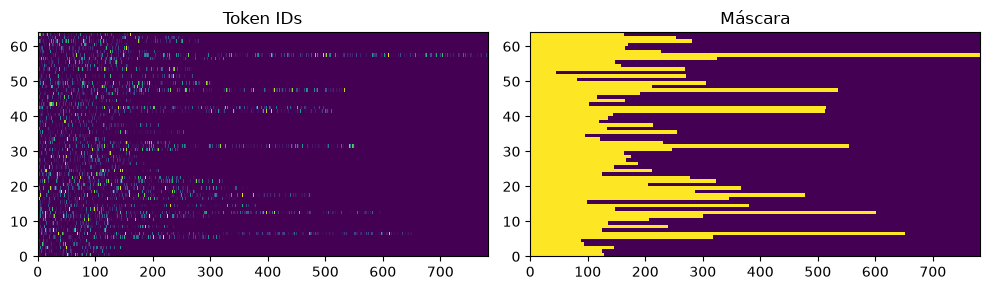

In [14]:
example_texts, example_labels = next(iter(train_data.batch(BATCH_SEQ)))
example_tokens = input_text_processor(example_texts)
print("Forma del lote vectorizado:", example_tokens.shape)
print(" ".join(input_vocab[example_tokens[0].numpy()]).strip()[:500], "...")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].pcolormesh(example_tokens); axes[0].set_title("Token IDs")
axes[1].pcolormesh(example_tokens != 0); axes[1].set_title("Máscara")
plt.tight_layout(); plt.show()

### Pipeline de datos

`make_seq_ds` aplica, en orden: barajado (solo en entrenamiento), agrupación en lotes, vectorización y **truncado a `MAX_LEN = 250` tokens** para acotar el coste de la recurrencia.

In [15]:
MAX_LEN = 250


def vectorize_text(text, label):
    return input_text_processor(text)[:, :MAX_LEN], label

def make_seq_ds(raw_ds, shuffle_=True, batch_=BATCH_SEQ):
    ds = raw_ds.shuffle(10_000, seed=SEED) if shuffle_ else raw_ds
    ds = ds.batch(batch_).map(vectorize_text, num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(AUTOTUNE)

seq_train = make_seq_ds(train_data, shuffle_=True)
seq_val   = make_seq_ds(validation_data, shuffle_=False)
seq_test  = make_seq_ds(test_data, shuffle_=False)

x, y = next(iter(seq_train))
print("tokens:", x.shape, x.dtype, "| etiquetas:", y.shape)

tokens: (64, 250) <dtype: 'int64'> | etiquetas: (64,)


### Modelos

Ambos modelos comparten la misma estructura y solo cambia el bloque recurrente: \


`Embedding(mask_zero=True)` | Convierte cada id en un vector denso de 64 dimensiones. \
**LSTM**  Una LSTM de 64 unidades que lee la reseña de izquierda a derecha y devuelve su último estado oculto. \
**BiLSTM**  Dos LSTM bidireccionales apiladas: cada una lee la secuencia en ambos sentidos y concatena los estados,

tf.keras.layers.LSTM(
    units,
    activation='tanh',
    recurrent_activation='sigmoid',
    use_bias=True,
    kernel_initializer='glorot_uniform',
    recurrent_initializer='orthogonal',
    bias_initializer='zeros',
    unit_forget_bias=True,
    kernel_regularizer=None,
    recurrent_regularizer=None,
    bias_regularizer=None,
    activity_regularizer=None,
    kernel_constraint=None,
    recurrent_constraint=None,
    bias_constraint=None,
    dropout=0.0,
    recurrent_dropout=0.0,
    seed=None,
    return_sequences=False,
    return_state=False,
    **kwargs)


In [ ]:
EMBED_DIM = 64

def build_text_model(bidirectional=False):
    if bidirectional:
        name = "IMDB_BiLSTM"
        recurrent = [layers.Bidirectional(layers.LSTM(64, return_sequences=True), name="bilstm1"),
                     layers.Bidirectional(layers.LSTM(32), name="bilstm2")]
    else:
        name = "IMDB_LSTM"
        recurrent = [layers.LSTM(64,return_sequences=True, name="lstm1"), 
                     layers.LSTM(32, name="lstm2")]

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(None,), dtype="int64"),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True, name="embedding"),
        *recurrent,
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, name="logit"),
    ], name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0, name="accuracy")],
    )
    return model

text_models = {"LSTM": build_text_model(False), "BiLSTM": build_text_model(True)}
for m in text_models.values():
    m.summary()

Model: "IMDB_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 64)       │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm1 (LSTM)                    │ (None, None, 64)       │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm2 (LSTM)                    │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 708,161 (2.70 MB)

 Trainable params: 708,161 (2.70 MB)

 Non-trainable params: 0 (0.00 B)

Model: "IMDB_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 64)       │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm1 (Bidirectional)         │ (None, None, 128)      │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm2 (Bidirectional)         │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 749,377 (2.86 MB)

 Trainable params: 749,377 (2.86 MB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento y evaluación

Se entrena cada modelo con `EarlyStopping` sobre `val_loss` (restaurando los mejores pesos). Con solo 2 épocas el *early stopping* apenas actúa; si se aumenta `EPOCHS_TXT` empieza a ser útil para cortar cuando la validación deja de mejorar.

In [17]:
EPOCHS_TXT = 2
hist_txt, test_results = {}, {}

for name, m in text_models.items():
    print(f"\n=== {name} ===")
    early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2)
    hist_txt[name] = m.fit(seq_train, validation_data=seq_val, epochs=EPOCHS_TXT, callbacks=[early_stop])
    test_results[name] = m.evaluate(seq_test, verbose=1)

pd.DataFrame(test_results).T


=== LSTM ===
Epoch 1/2


c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


235/235 ━━━━━━━━━━━━━━━━━━━━ 78s 291ms/step - accuracy: 0.7361 - loss: 0.5136 - val_accuracy: 0.8247 - val_loss: 0.4120
Epoch 2/2
235/235 ━━━━━━━━━━━━━━━━━━━━ 71s 301ms/step - accuracy: 0.8764 - loss: 0.3171 - val_accuracy: 0.8354 - val_loss: 0.4109
391/391 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.8186 - loss: 0.4363

=== BiLSTM ===
Epoch 1/2
235/235 ━━━━━━━━━━━━━━━━━━━━ 127s 474ms/step - accuracy: 0.7534 - loss: 0.4746 - val_accuracy: 0.8585 - val_loss: 0.3313
Epoch 2/2
235/235 ━━━━━━━━━━━━━━━━━━━━ 106s 452ms/step - accuracy: 0.8987 - loss: 0.2584 - val_accuracy: 0.8445 - val_loss: 0.3813
391/391 ━━━━━━━━━━━━━━━━━━━━ 37s 95ms/step - accuracy: 0.8346 - loss: 0.4037


,0,1
LSTM,0.436302,0.81864
BiLSTM,0.403718,0.83464


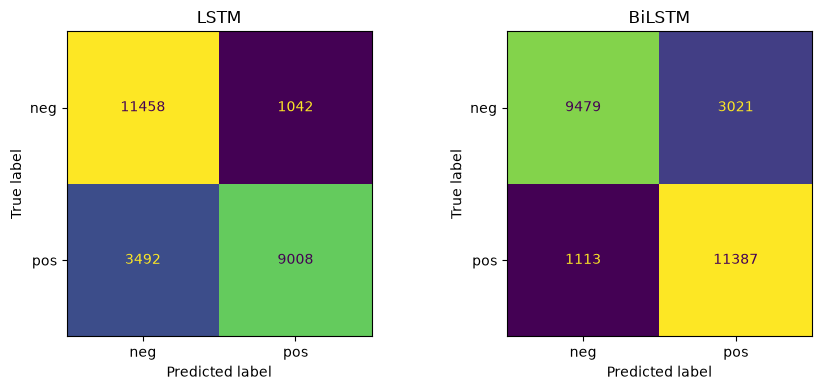

In [18]:
y_true = np.concatenate([y.numpy() for _, y in seq_test])
fig, axes = plt.subplots(1, len(text_models), figsize=(9, 4))
for ax, (name, m) in zip(axes, text_models.items()):
    y_pred = (m.predict(seq_test, verbose=0).ravel() > 0).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["neg", "pos"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

---
## Pronóstico de manchas solares

**Datos.** Número medio mensual de manchas solares 

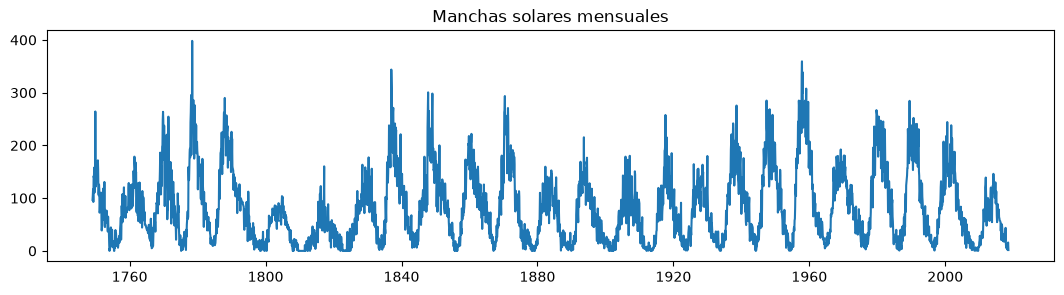

In [19]:
filepath = pathlib.Path("../clase1/sunspots.csv")
df = pd.read_csv(filepath)

value_col = "Monthly Mean Total Sunspot Number"
assert value_col in df.columns, f"No se encuentra {value_col}. Columnas: {df.columns.tolist()}"
series = df[value_col].to_numpy(dtype="float32")
dates = pd.to_datetime(df["Date"])

plt.figure(figsize=(13, 3)); plt.plot(dates, series)
plt.title("Manchas solares mensuales"); plt.show()

### División temporal, normalización y ventanas

- **División cronológica** 70 / 15 / 15 (train / valid / test). 
- **Normalización** con media y desviación estándar calculadas **solo en entrenamiento** 

In [20]:
WINDOW_SIZE = 60
BATCH_TS = 32

n = len(series)
train_end, val_end = int(n * 0.70), int(n * 0.85)
mu = float(series[:train_end].mean())
sigma = max(float(series[:train_end].std()), 1e-6)
series_norm = (series - mu) / sigma
print("train / valid / test:", train_end, val_end - train_end, n - val_end)

def make_windows(values, target_start, target_end, window=WINDOW_SIZE):
    targets = np.arange(max(target_start, window), target_end)
    X = np.stack([values[t - window:t] for t in targets])[..., np.newaxis]
    y = values[targets, np.newaxis]
    return X.astype("float32"), y.astype("float32"), targets

def to_ts_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(1024, seed=SEED)
    return ds.batch(BATCH_TS).prefetch(AUTOTUNE)

X_train, y_train, idx_train = make_windows(series_norm, 0, train_end)
X_val,   y_val,   idx_val   = make_windows(series_norm, train_end, val_end)
X_test,  y_test,  idx_test  = make_windows(series_norm, val_end, n)

train_ts = to_ts_dataset(X_train, y_train, training=True)
val_ts   = to_ts_dataset(X_val, y_val)
print("Ventanas:", X_train.shape, X_val.shape, X_test.shape)

train / valid / test: 2264 485 486
Ventanas: (2204, 60, 1) (485, 60, 1) (486, 60, 1)


### Modelos: LSTM vs GRU

Se usa la misma arquitectura cambiando solo la celda recurrente:

- **LSTM**: tres puertas (entrada, olvido, salida).
- **GRU**: dos puertas.

In [ ]:
EPOCHS_TS = 10

def build_ts_model(cell="lstm"):
    RNN = {"lstm": layers.LSTM, "gru": layers.GRU}[cell]
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(WINDOW_SIZE, 1)),
        RNN(64, return_sequences=True),
        RNN(32),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ], name=f"Sunspots_{cell.upper()}")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss=tf.keras.losses.Huber(), metrics=["mae"])
    return model

ts_models, hist_ts = {}, {}
for name in ["LSTM", "GRU"]:
    print(f"{name}")
    model = build_ts_model(name.lower())
    model.summary()
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4)]
    hist_ts[name] = model.fit(train_ts, validation_data=val_ts, epochs=EPOCHS_TS, callbacks=callbacks, verbose=1)
    ts_models[name] = model


=== LSTM ===


Model: "Sunspots_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - loss: 0.1344 - mae: 0.3881 - val_loss: 0.0997 - val_mae: 0.3388 - learning_rate: 0.0010
Epoch 2/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0830 - mae: 0.2972 - val_loss: 0.0983 - val_mae: 0.3288 - learning_rate: 0.0010
Epoch 3/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.0797 - mae: 0.2901 - val_loss: 0.0884 - val_mae: 0.3159 - learning_rate: 0.0010
Epoch 4/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0765 - mae: 0.2834 - val_loss: 0.0878 - val_mae: 0.3107 - learning_rate: 0.0010
Epoch 5/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 0.0762 - mae: 0.2837 - val_loss: 0.0874 - val_mae: 0.3078 - learning_rate: 0.0010
Epoch 6/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.0764 - mae: 0.2825 - val_loss: 0.0892 - val_mae: 0.3100 - learning_rate: 0.0010
Epoch 7/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0753 - mae: 0.2811 - val_loss: 0.0862 - val_mae: 0.3069 - learning_rate: 0.0010
Epoch 8/10
6

### Evaluación en test

                    MAE       RMSE
LSTM          18.328342  24.485704
GRU           17.775581  24.241907
Persistencia  19.349998  26.879732


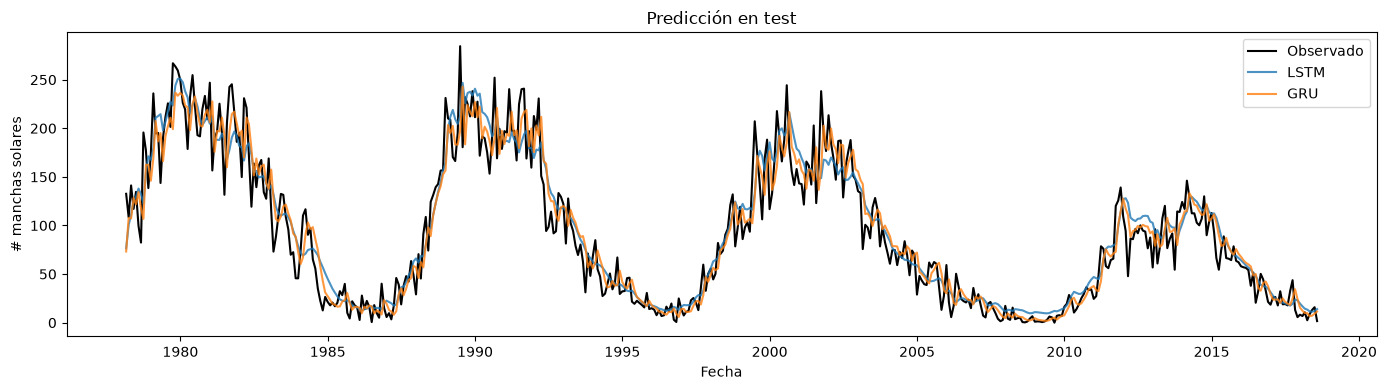

In [ ]:
actual = y_test.ravel() * sigma + mu

def forecast_metrics(predicted):
    err = actual - predicted
    return {"MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err**2)))}

preds = {name: m.predict(X_test, verbose=0).ravel() * sigma + mu for name, m in ts_models.items()}
preds["Persistencia"] = X_test[:, -1, 0] * sigma + mu 

print(pd.DataFrame({name: forecast_metrics(p) for name, p in preds.items()}).T)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dates.iloc[idx_test], actual, label="Observado", color="black", lw=1.5)
for name in ts_models:
    ax.plot(dates.iloc[idx_test], preds[name], label=name, alpha=.8)
ax.set(xlabel="Fecha", ylabel="# manchas solares", title="Predicción en test")
ax.legend(); plt.tight_layout(); plt.show()